<a href="https://colab.research.google.com/github/Krishna9423-wagh/numpy_projects/blob/main/monte_carlo_portfolio_risk_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Set the seed and per-asset daily mean and volatility

In [5]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

assets  = ["Stock A", "Stock B", "Bond", "Gold"]
mu      = np.array([0.0007, 0.0005, 0.0002, 0.0003])
sigma   = np.array([0.012,  0.010,  0.003,  0.008])
weights = np.array([0.40, 0.30, 0.20, 0.10])

n_sims, n_days, n_assets = 10_000, 252, 4
initial_value = 100_000

Simulate 10,000 × 252 × 4 returns with np.random.normal

In [6]:
returns = np.random.normal(mu, sigma, size=(n_sims, n_days, n_assets))
print(returns.shape)

(10000, 252, 4)


Portfolio paths with matrix product, log1p and exp

In [7]:

port_daily = returns @ weights


growth = np.exp(np.cumsum(np.log1p(port_daily), axis=1))
paths  = initial_value * growth

final_values = paths[:, -1]

Histogram, volatility and 95% VaR

Expected final value : 113,386
Annualized volatility: 9.12%
95% VaR (1 year)     : 3,028 (3.03% of portfolio)


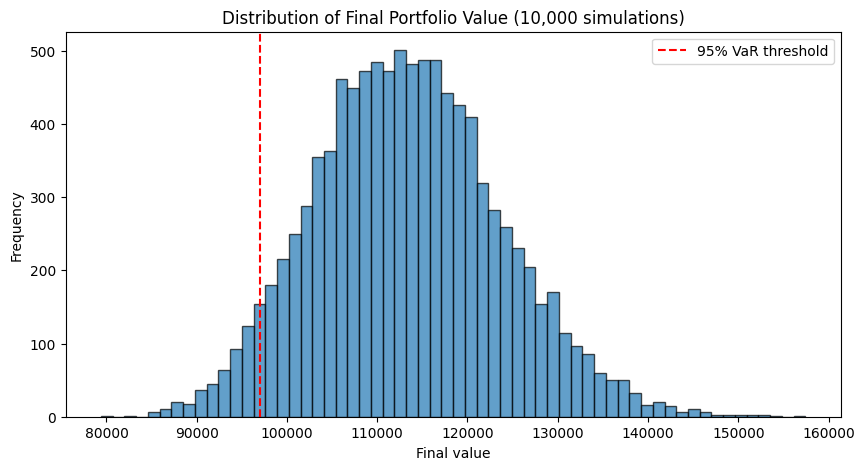

In [8]:
final_returns = final_values / initial_value - 1


annual_vol = port_daily.std() * np.sqrt(252)


losses = initial_value - final_values
var_95 = np.percentile(losses, 95)

print(f"Expected final value : {final_values.mean():,.0f}")
print(f"Annualized volatility: {annual_vol:.2%}")
print(f"95% VaR (1 year)     : {var_95:,.0f} ({var_95/initial_value:.2%} of portfolio)")

plt.figure(figsize=(10,5))
plt.hist(final_values, bins=60, edgecolor="black", alpha=0.7)
plt.axvline(initial_value - var_95, color="red", linestyle="--", label="95% VaR threshold")
plt.title("Distribution of Final Portfolio Value (10,000 simulations)")
plt.xlabel("Final value"); plt.ylabel("Frequency"); plt.legend()
plt.show()